## **Road Accident Risk - Exploratory Data Analysis (EDA)**

**This notebook performs a comprehensive exploratory data analysis of the road accident risk dataset. We'll explore:**
1. Data Overview & Quality Checks
2. Numerical Features Distribution
3. Categorical Features Analysis
4. Correlation Analysis
5. Target Variable Relationships

In [1]:
# ===============================
# IMPORT LIBRARIES
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from matplotlib.colors import LinearSegmentedColormap
import warnings

# ===============================
# CUSTOM COLORS
# ===============================
custom_colors = ["#c80000", "#dcdddd", "#ffa27f", "#006f7a"]

# Custom colormap for numerical gradient (small -> green, large -> red)
custom_cmap = LinearSegmentedColormap.from_list(
    "custom_cmap", ["#006f7a", "#ffa27f", "#dcdddd", "#c80000"]
)

# ===============================
# SEABORN STYLE
# ===============================
sns.set_theme(style="whitegrid", palette=sns.color_palette(custom_colors))
sns.set_style("whitegrid", {"grid.linestyle": ":"})

# ===============================
# MATPLOTLIB PARAMETERS
# ===============================
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 100,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=custom_colors)
})

# ===============================
# WARNINGS
# ===============================
warnings.filterwarnings('ignore')


### **1. Data Overview & Quality Checks**

In [2]:
# Read the training dataset
df = pd.read_csv('../data/train.csv')

In [3]:
# Display basic information about the dataset
print("Dataset Overview:")
print(f"Number of samples: {df.shape[0]:,}")
print(f"Number of features: {df.shape[1]:,}")
print("\nFeature names:")
print(df.columns.tolist())

Dataset Overview:
Number of samples: 517,754
Number of features: 14

Feature names:
['id', 'road_type', 'num_lanes', 'curvature', 'speed_limit', 'lighting', 'weather', 'road_signs_present', 'public_road', 'time_of_day', 'holiday', 'school_season', 'num_reported_accidents', 'accident_risk']


In [4]:
# Display the first few rows of the dataset with enhanced formatting
display(
    df.head(10)
      .style
      .background_gradient(cmap=custom_cmap, subset=['accident_risk'])
      .set_properties(**{'font-size': '11pt'})
      .set_table_styles([{'selector': 'th', 'props': [('font-size', '11pt'), ('text-align', 'center')]}])
)


,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
0,0,urban,2,0.060000,35,daylight,rainy,False,True,afternoon,False,True,1,0.130000
1,1,urban,4,0.990000,35,daylight,clear,True,False,evening,True,True,0,0.350000
2,2,rural,4,0.630000,70,dim,clear,False,True,morning,True,False,2,0.300000
3,3,highway,4,0.070000,35,dim,rainy,True,True,morning,False,False,1,0.210000
4,4,rural,1,0.580000,60,daylight,foggy,False,False,evening,True,False,1,0.560000
5,5,highway,3,0.540000,70,night,foggy,True,False,morning,False,True,0,0.610000
6,6,highway,1,0.040000,45,night,foggy,False,True,morning,True,False,2,0.200000
7,7,highway,2,0.330000,45,daylight,clear,False,True,evening,False,True,0,0.160000
8,8,rural,3,0.630000,25,dim,clear,True,False,evening,True,True,2,0.180000
9,9,urban,4,0.380000,45,dim,clear,True,True,afternoon,True,True,2,0.150000


In [5]:
print(f'Dataset shape: {df.shape}')

Dataset shape: (517754, 14)


In [6]:
print(f'Dataset dtypes: {set(df.dtypes)}')

Dataset dtypes: {dtype('bool'), dtype('float64'), dtype('int64'), dtype('O')}


In [7]:
# Detailed analysis of data types and memory usage
print("Detailed Dataset Information:")
df.info(memory_usage='deep')

Detailed Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517754 entries, 0 to 517753
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      517754 non-null  int64  
 1   road_type               517754 non-null  object 
 2   num_lanes               517754 non-null  int64  
 3   curvature               517754 non-null  float64
 4   speed_limit             517754 non-null  int64  
 5   lighting                517754 non-null  object 
 6   weather                 517754 non-null  object 
 7   road_signs_present      517754 non-null  bool   
 8   public_road             517754 non-null  bool   
 9   time_of_day             517754 non-null  object 
 10  holiday                 517754 non-null  bool   
 11  school_season           517754 non-null  bool   
 12  num_reported_accidents  517754 non-null  int64  
 13  accident_risk           517754 non-null  flo

In [8]:
# Check for missing values and calculate percentage
missing_values = df.isnull().sum()
missing_percentages = (missing_values / len(df)) * 100

# Create a summary DataFrame of missing values
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentages
}).query('`Missing Values` > 0')

if not missing_summary.empty:
    print("Missing Values Summary:")
    print(missing_summary)
else:
    print("No missing values found in the dataset")

No missing values found in the dataset


In [9]:
# Check for duplicate rows and provide details
duplicate_count = df.duplicated().sum()
print("Duplicate Rows Analysis:")
print(f"Total duplicate rows: {duplicate_count:,}")
print(f"Percentage of duplicates: {(duplicate_count/len(df))*100:.2f}%")

if duplicate_count > 0:
    print("\nFirst few duplicate rows:")
    display(df[df.duplicated(keep='first')].head())

Duplicate Rows Analysis:
Total duplicate rows: 0
Percentage of duplicates: 0.00%


In [10]:
df.describe()

,id,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
count,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000,517754.000000
mean,258876.500000,2.491511,0.488719,46.112575,1.187970,0.352377
std,149462.849974,1.120434,0.272563,15.788521,0.895961,0.166417
min,0.000000,1.000000,0.000000,25.000000,0.000000,0.000000
25%,129438.250000,1.000000,0.260000,35.000000,1.000000,0.230000
50%,258876.500000,2.000000,0.510000,45.000000,1.000000,0.340000
75%,388314.750000,3.000000,0.710000,60.000000,2.000000,0.460000
max,517753.000000,4.000000,1.000000,70.000000,7.000000,1.000000


In [11]:
df.describe(include=['object', 'bool'])

,road_type,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season
count,517754,517754,517754,517754,517754,517754,517754,517754
unique,3,3,3,2,2,3,2,2
top,highway,dim,foggy,False,True,morning,True,False
freq,173672,183826,181463,259289,260045,173410,260688,260164


### **2. Numerical Features Distribution**

In [12]:
num_cols = ["num_lanes", "curvature", "speed_limit", "num_reported_accidents"]

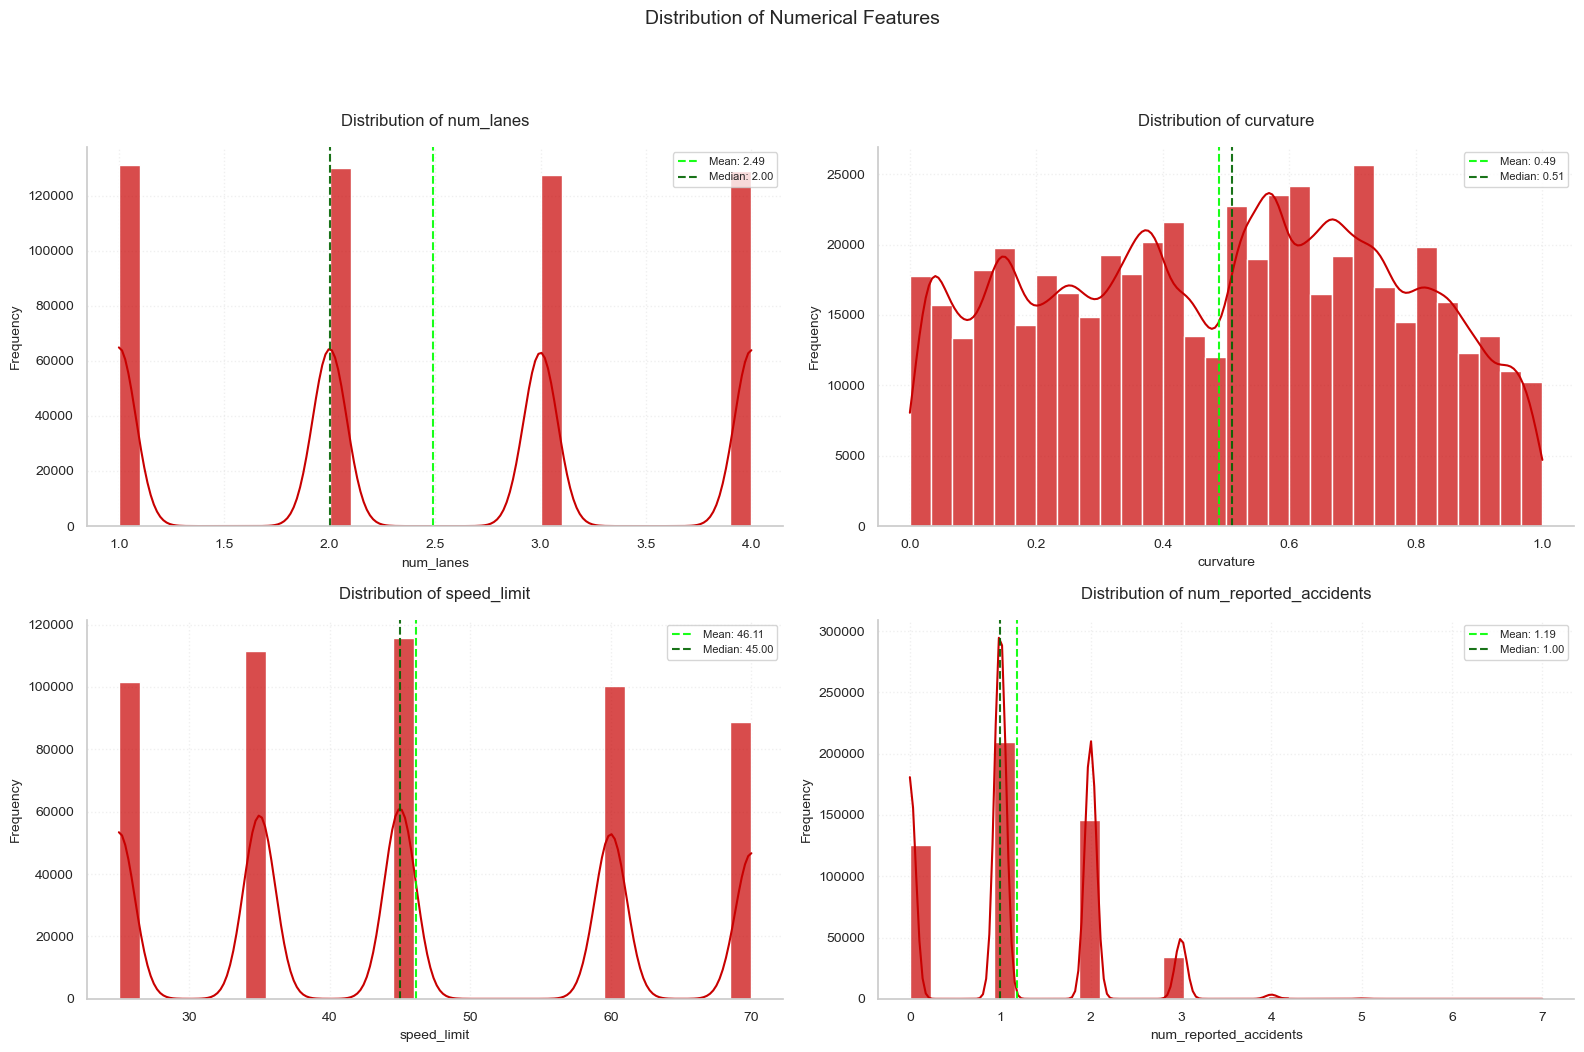

In [13]:
# Create histograms for numerical features
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i], 
                 color=custom_colors[0], alpha=0.7)
    
    mean_val = df[col].mean()
    median_val = df[col].median()
    axes[i].axvline(mean_val, color='#00ff00', linestyle='--', alpha=0.9, label=f'Mean: {mean_val:.2f}')
    axes[i].axvline(median_val, color='#006400', linestyle='--', alpha=0.9, label=f'Median: {median_val:.2f}')
    
    axes[i].set_title(f"Distribution of {col}", pad=15, fontsize=12)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribution of Numerical Features", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()


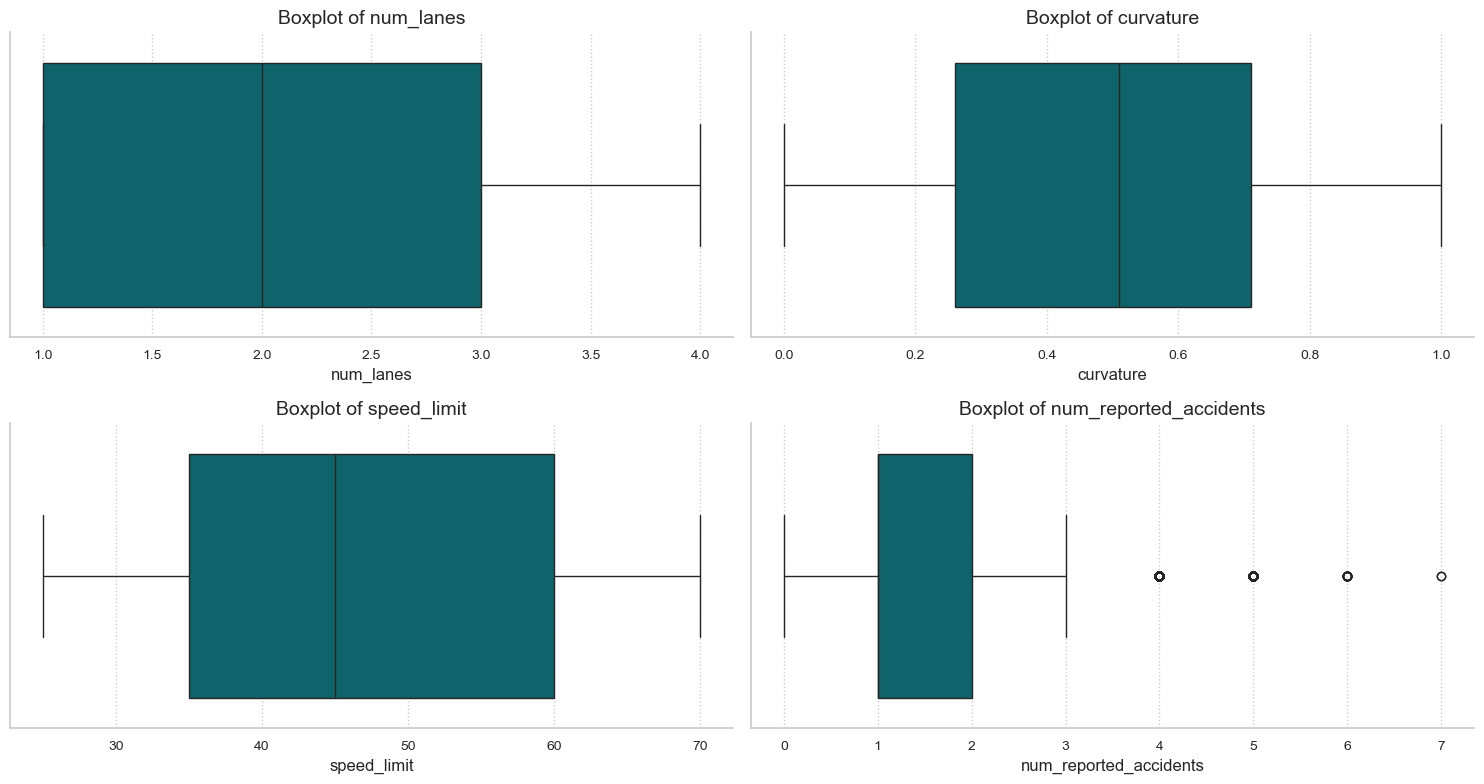

In [14]:
# Boxplots for numerical features
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color=custom_colors[3])
    axes[i].set_title(f"Boxplot of {col}")

for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### **3. Categorical Features Analysis**

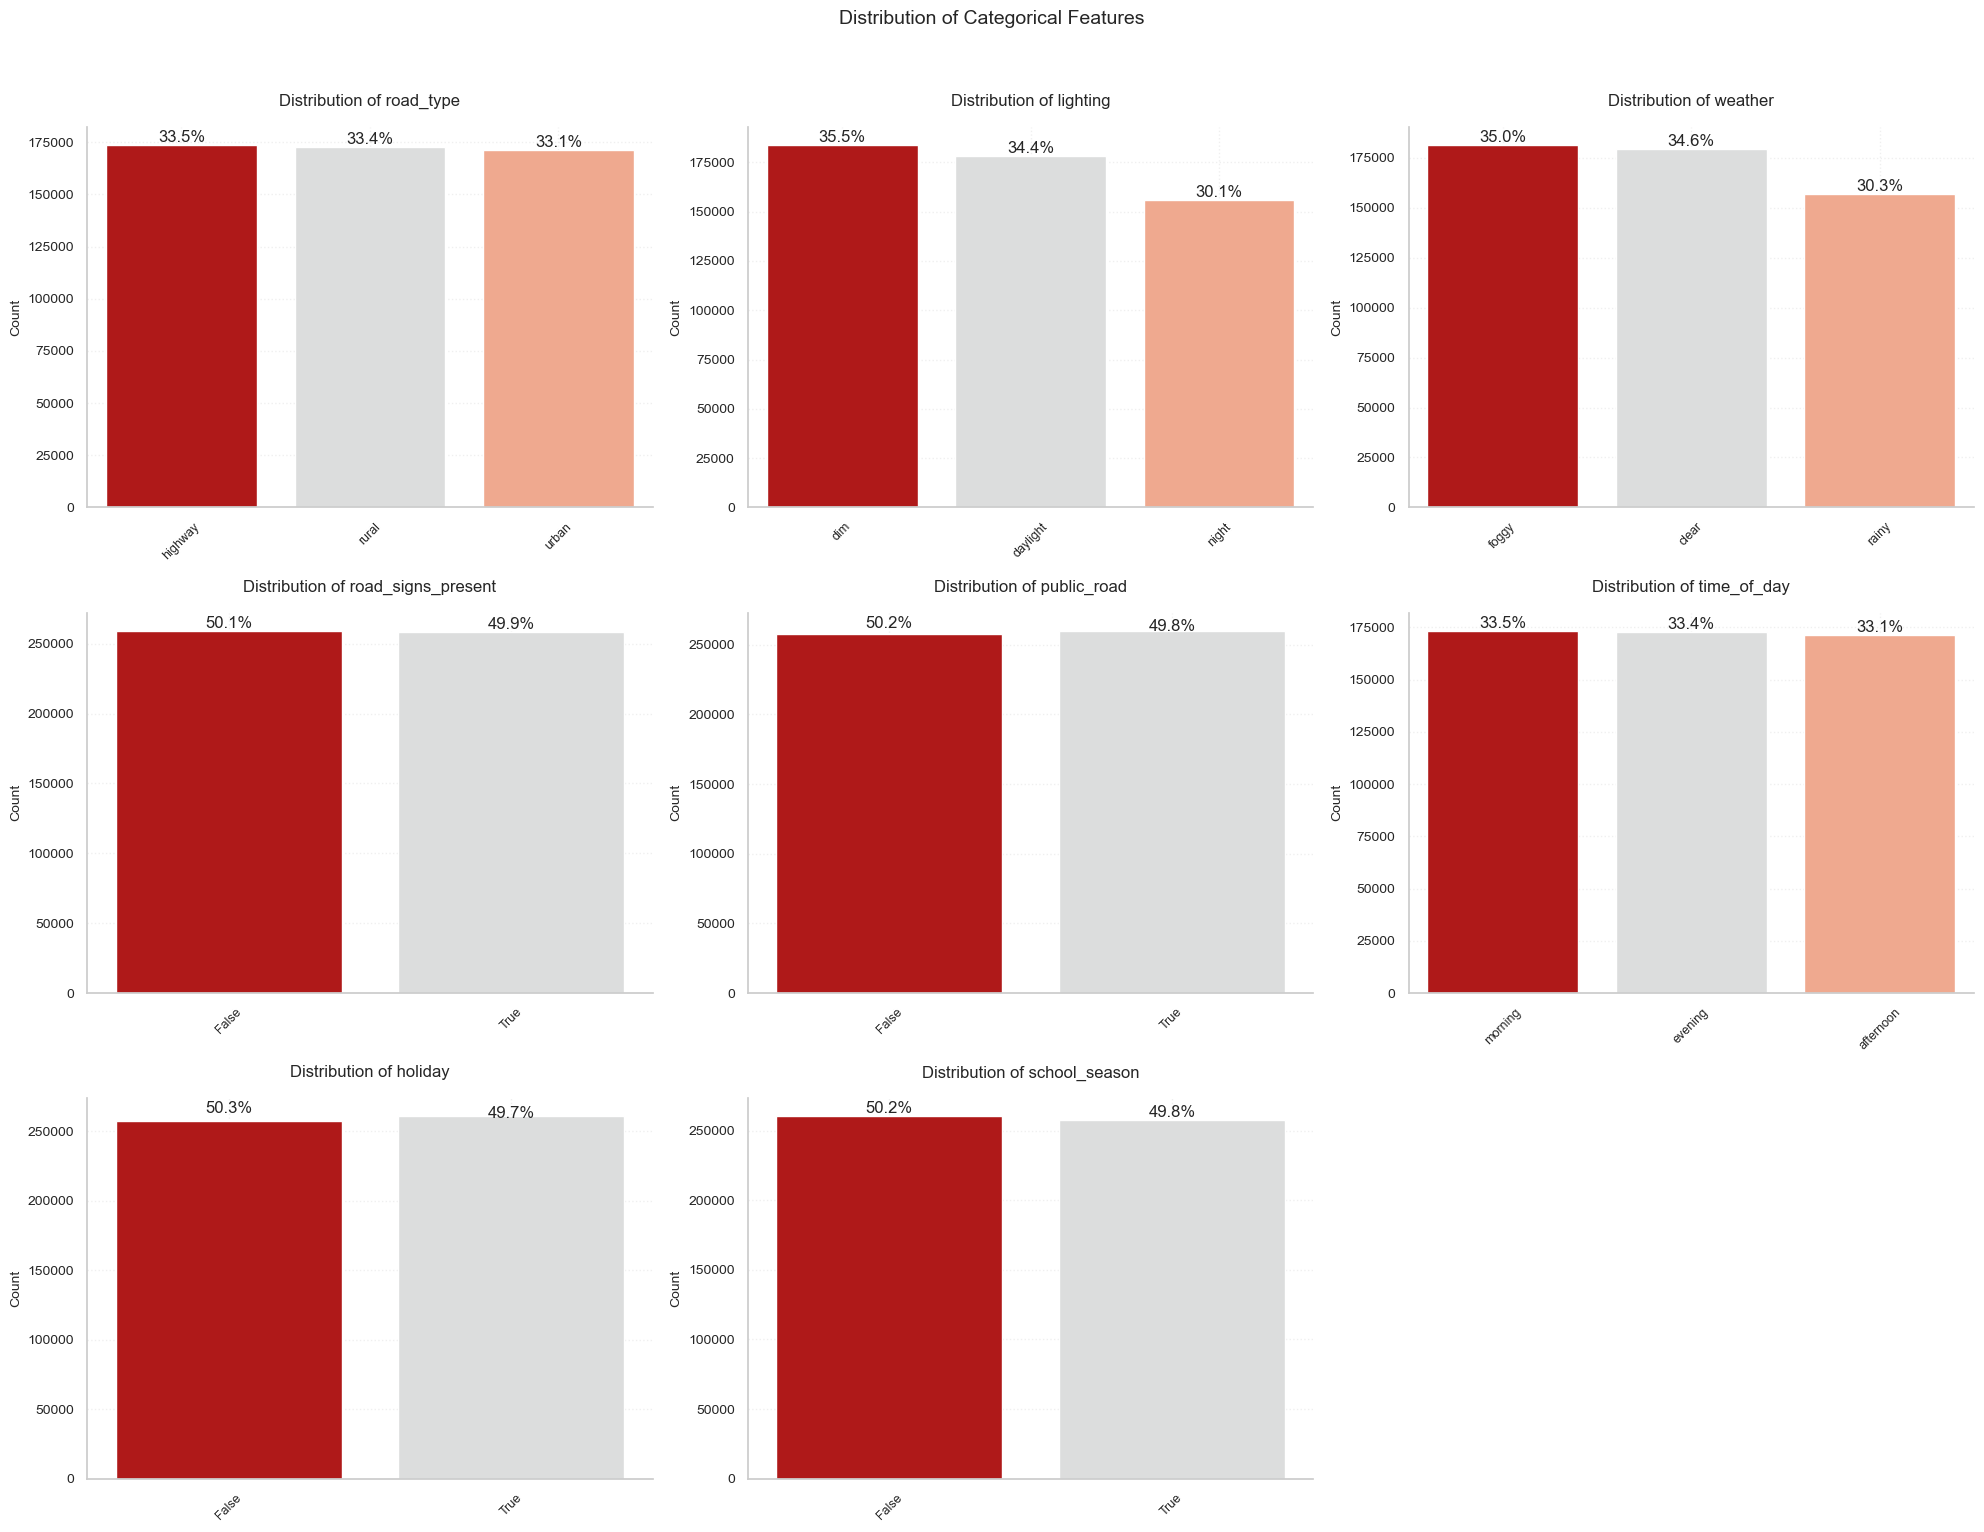

In [15]:
# Visualization of categorical features
cat_cols = df.select_dtypes(include=['object', 'bool']).columns.tolist()

# Calculate number of rows and columns needed for subplots
n_cols = 3
n_rows = (len(cat_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten()

# Custom color palette
colors = custom_colors

for i, col in enumerate(cat_cols):
    value_counts = df[col].value_counts()
    total = len(df)
    
    sns.barplot(x=value_counts.index, y=value_counts.values, 
                ax=axes[i], palette=colors)
    
    for j, v in enumerate(value_counts.values):
        axes[i].text(j, v, f'{(v/total)*100:.1f}%', 
                     ha='center', va='bottom')
    
    axes[i].set_title(f"Distribution of {col}", pad=15, fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count", fontsize=10)
    axes[i].tick_params(axis='x', rotation=45, labelsize=9)
    axes[i].grid(True, alpha=0.3)

for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribution of Categorical Features", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


### **4. Correlation Analysis**

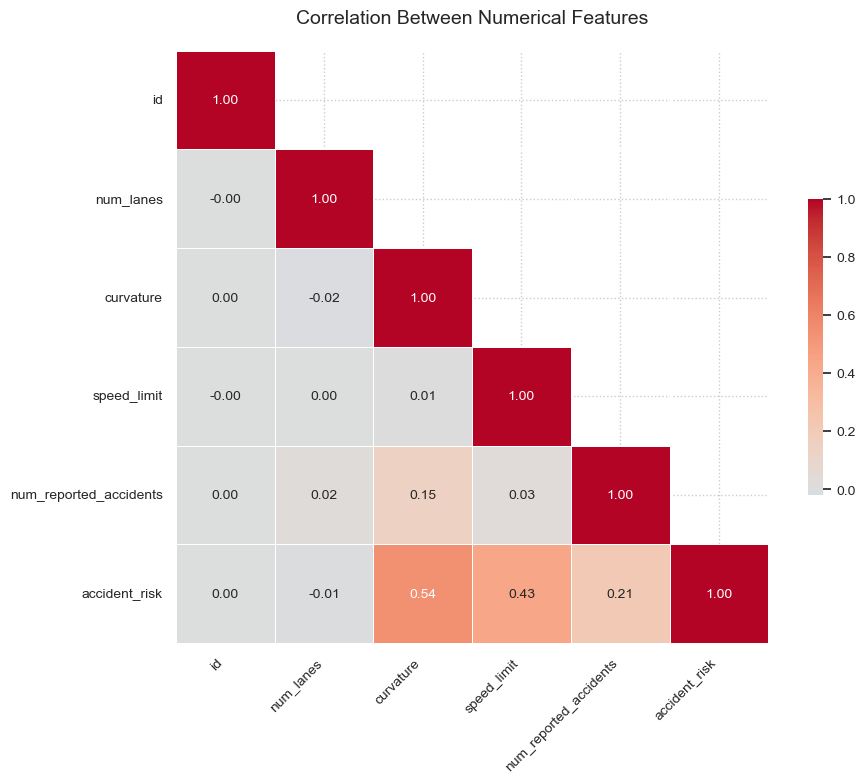

In [16]:
# Create a correlation heatmap for numerical features
plt.figure(figsize=(10, 8))

# Select numerical columns
num_df = df.select_dtypes(include=['number'])

# Calculate correlation matrix
corr_matrix = num_df.corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix), k=1)

# Create heatmap with improved styling
sns.heatmap(corr_matrix, 
            mask=mask,
            annot=True, 
            fmt=".2f",
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": .5},
            annot_kws={"size": 10})

plt.title("Correlation Between Numerical Features", pad=20, fontsize=14)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

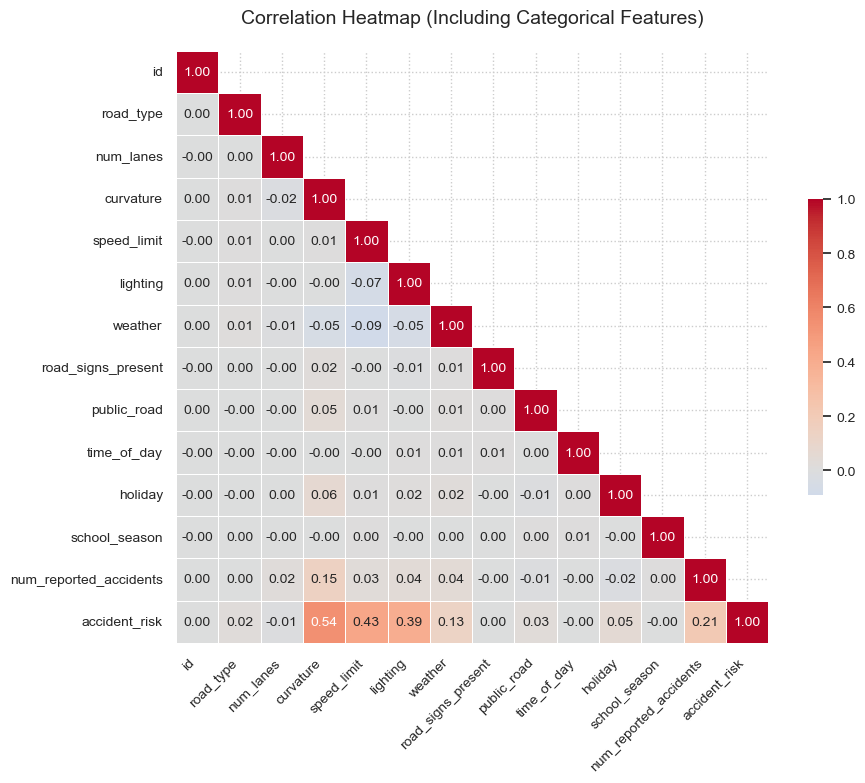

In [17]:
# Encode categorical features
encoded_df = df.copy()
for col in cat_cols:
    encoded_df[col] = encoded_df[col].astype('category').cat.codes

# Select numerical columns (including encoded categories)
corr_matrix = encoded_df.corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(corr_matrix), k=1)

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": .5},
            annot_kws={"size": 10})

# Title and axis styling
plt.title("Correlation Heatmap (Including Categorical Features)", pad=20, fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### **5. Target Variable Relationships**

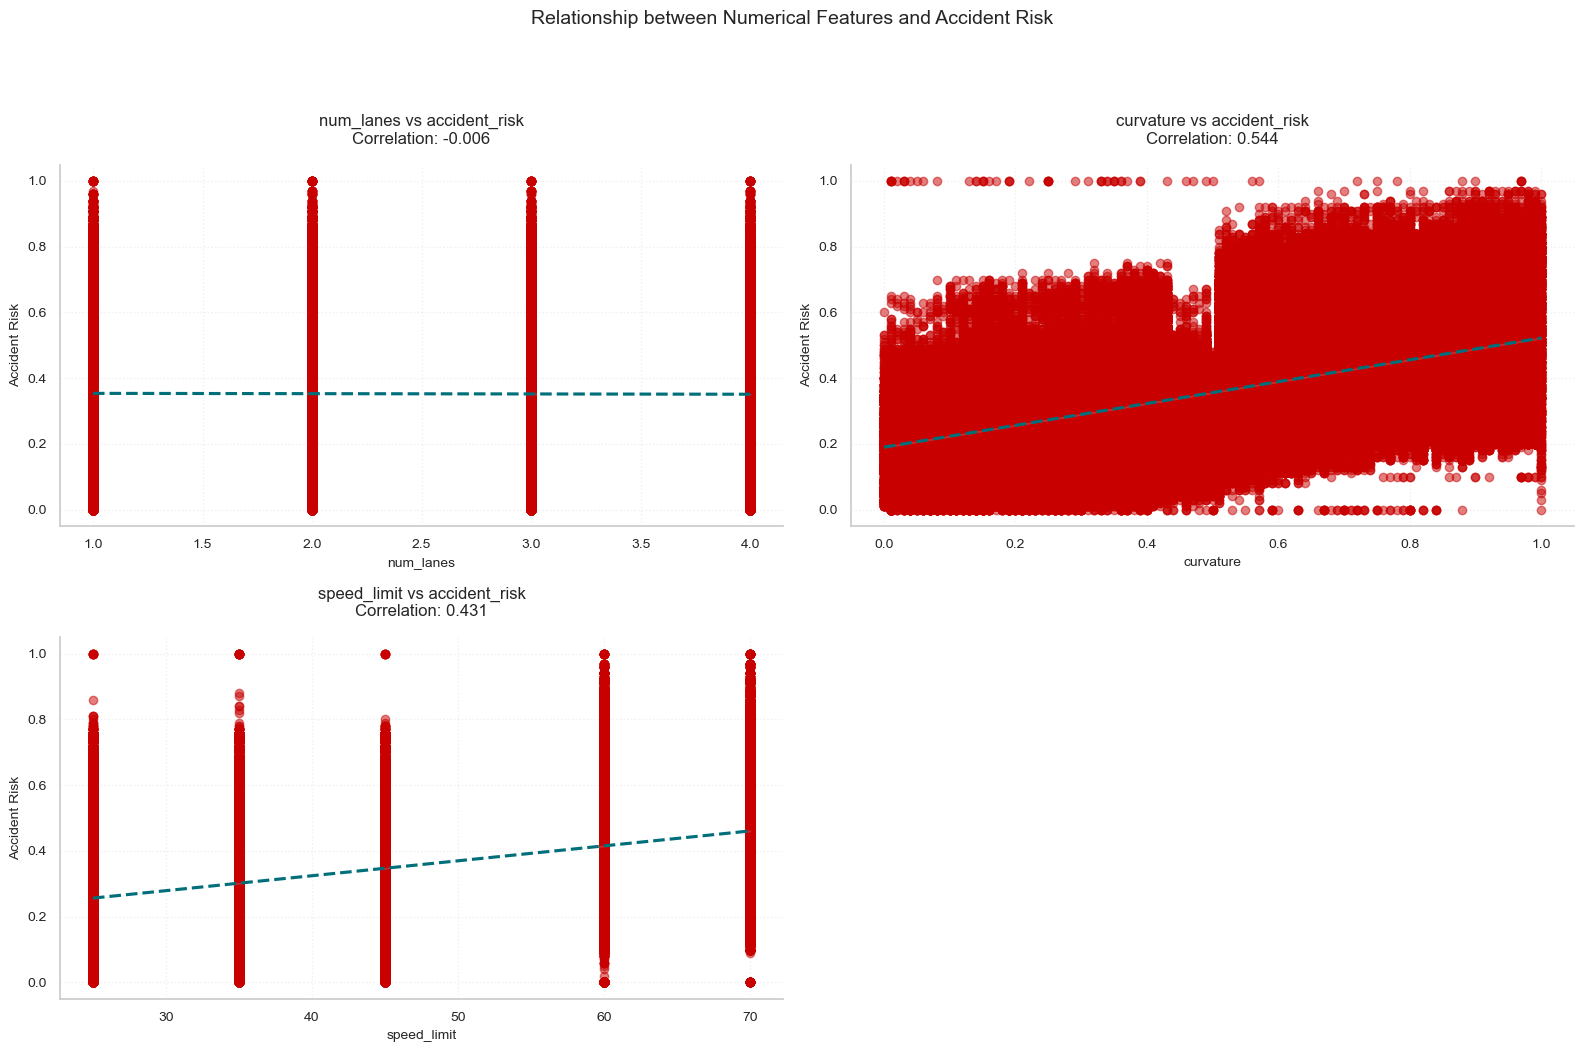


Statistical Summary of Relationships with Accident Risk:
--------------------------------------------------

num_lanes:
- Correlation coefficient: -0.006
- Spearman rank correlation: -0.007

curvature:
- Correlation coefficient: 0.544
- Spearman rank correlation: 0.547

speed_limit:
- Correlation coefficient: 0.431
- Spearman rank correlation: 0.409


In [18]:
# Create enhanced scatter plots for numerical features vs target
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(num_cols[:-1]):
    sns.regplot(
        data=df, x=col, y="accident_risk", ax=axes[i],
        scatter_kws={'alpha':0.5, 'color': custom_colors[0]},
        line_kws={'color': custom_colors[3], 'linestyle':'--'}
    )
    
    corr = df[col].corr(df['accident_risk'])
    
    axes[i].set_title(f"{col} vs accident_risk\nCorrelation: {corr:.3f}", 
                     pad=15, fontsize=12)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel("Accident Risk", fontsize=10)
    axes[i].grid(True, alpha=0.3)

for j in range(len(num_cols)-1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Relationship between Numerical Features and Accident Risk", 
             y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

print("\nStatistical Summary of Relationships with Accident Risk:")
print("-" * 50)
for col in num_cols[:-1]:
    correlation = df[col].corr(df['accident_risk'])
    print(f"\n{col}:")
    print(f"- Correlation coefficient: {correlation:.3f}")
    print(f"- Spearman rank correlation: {df[col].corr(df['accident_risk'], method='spearman'):.3f}")


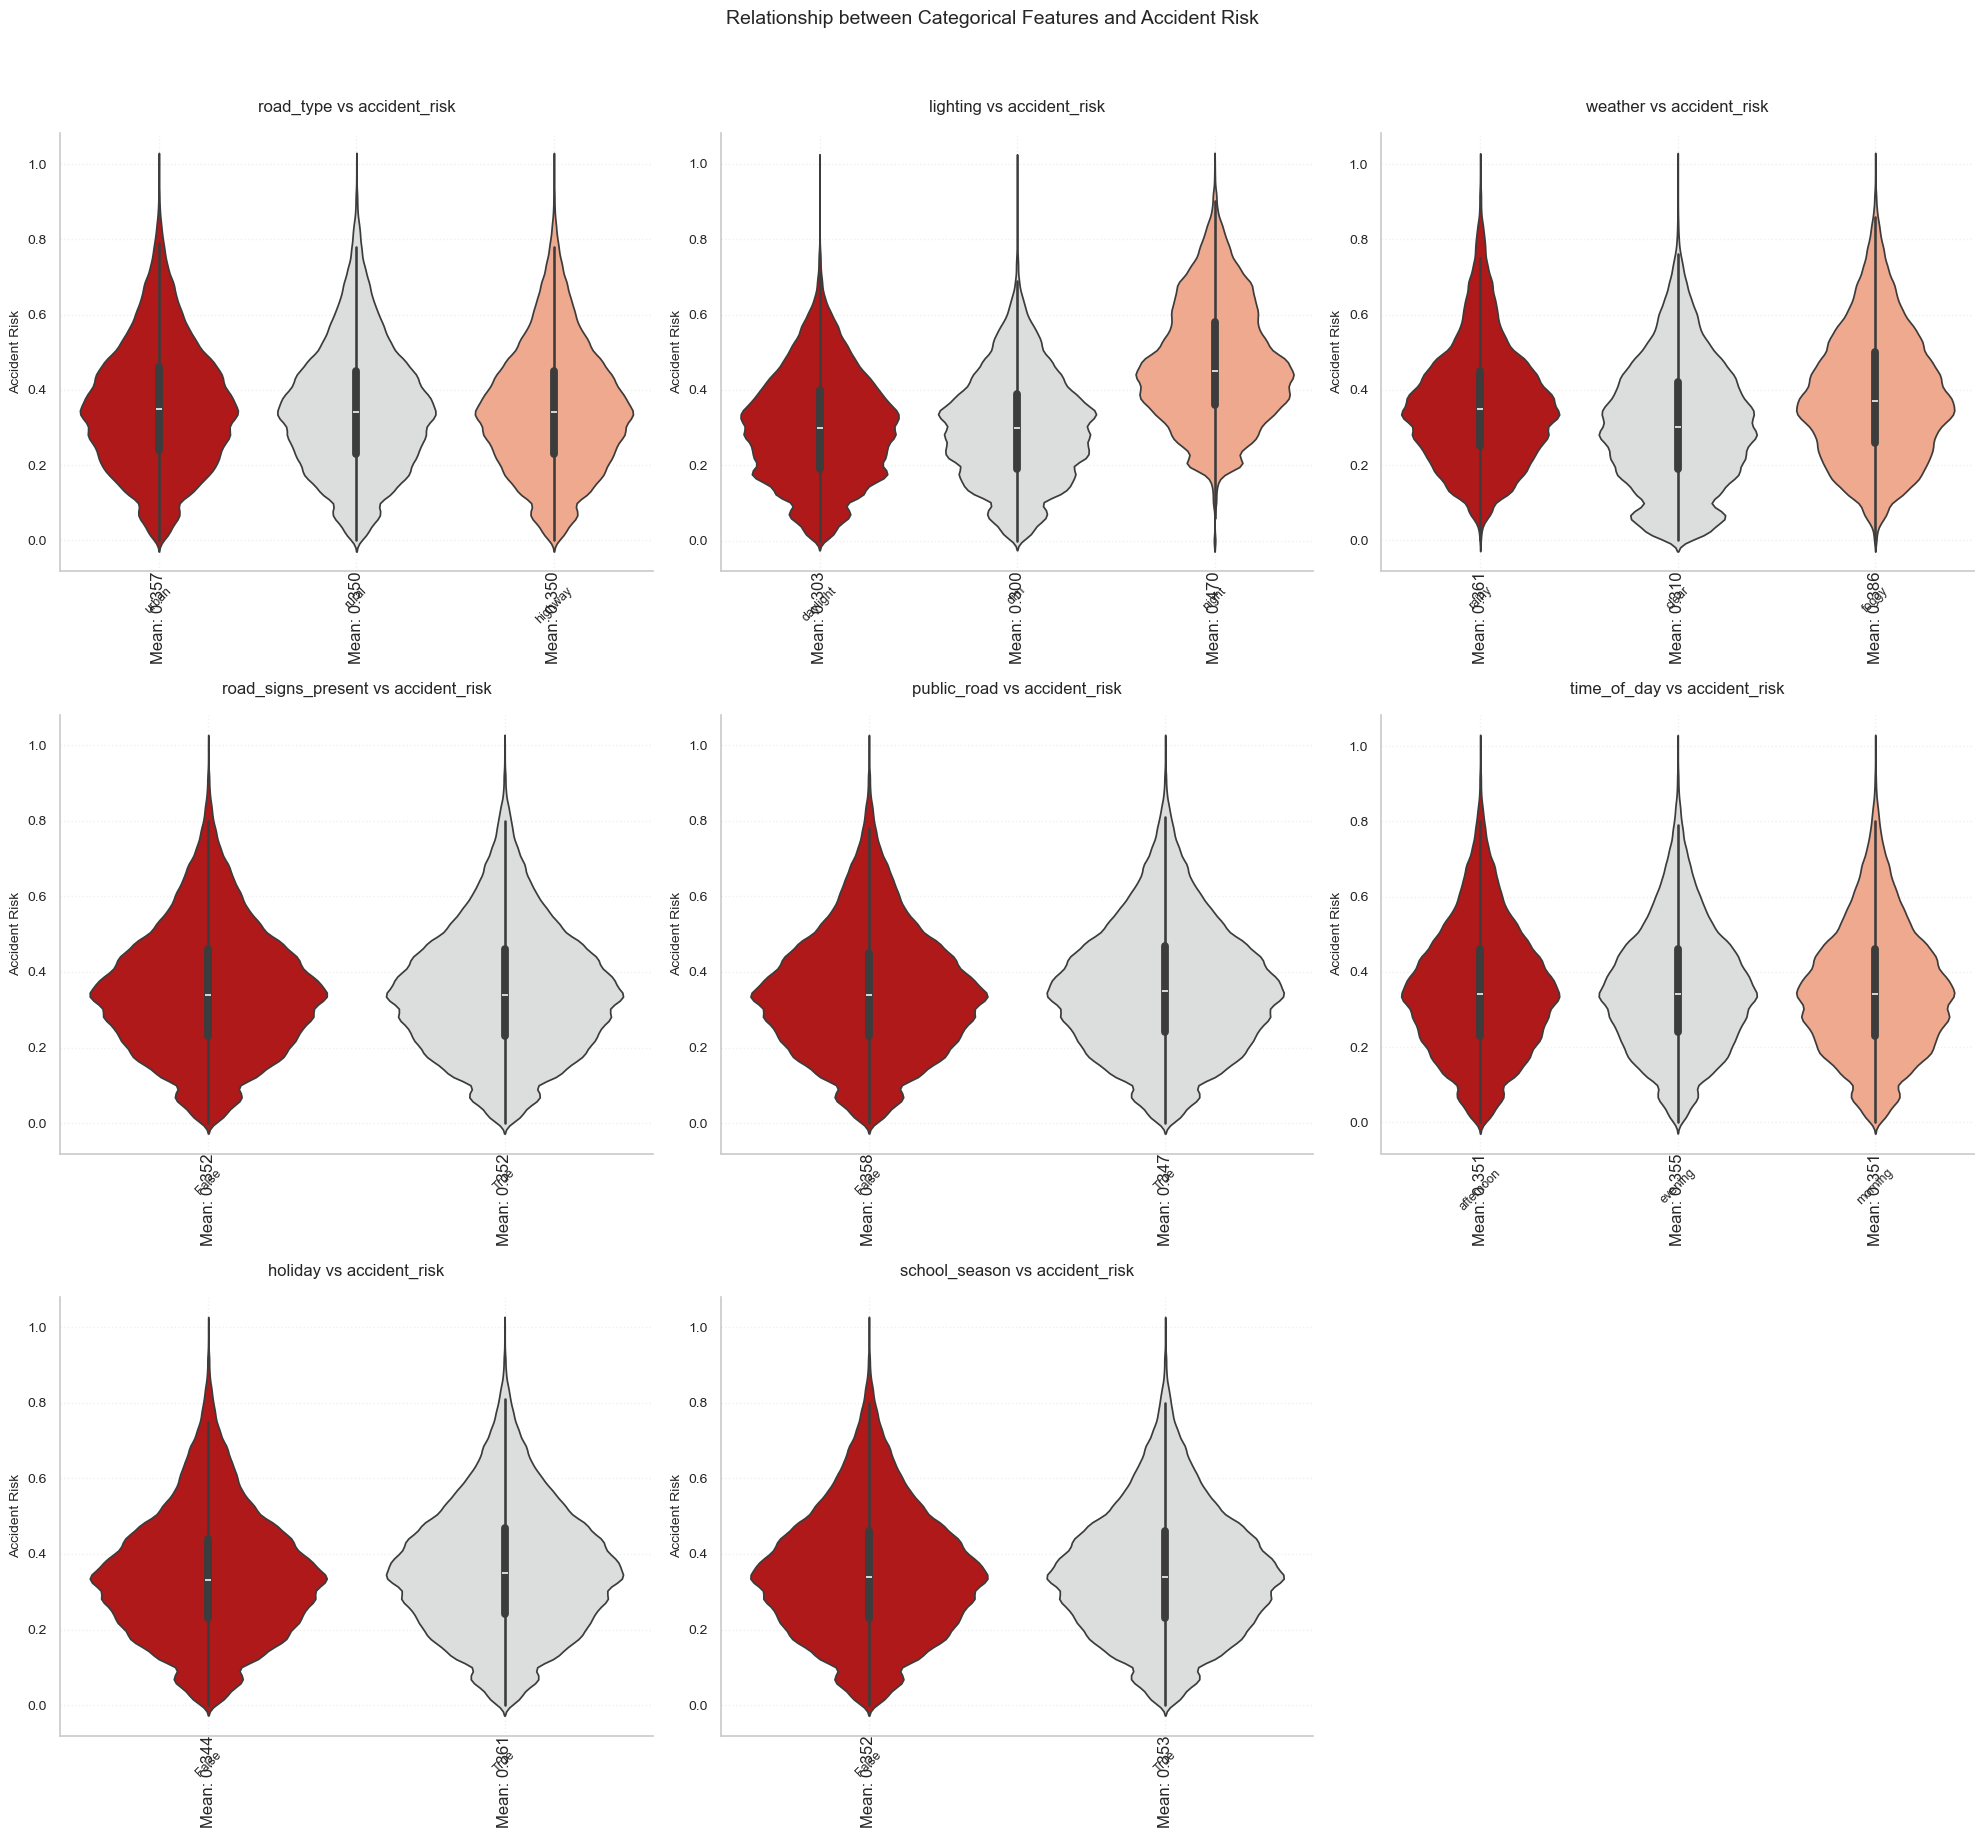


Statistical Analysis of Categorical Features vs Accident Risk:
--------------------------------------------------

road_type:
            mean    std   count
road_type                      
highway    0.350  0.166  173672
rural      0.350  0.167  172719
urban      0.357  0.166  171363

ANOVA Test:
F-statistic: 119.422
p-value: 1.405e-52

lighting:
           mean    std   count
lighting                      
daylight  0.303  0.143  178015
dim       0.300  0.142  183826
night     0.470  0.158  155913

ANOVA Test:
F-statistic: 71752.063
p-value: 0.000e+00

weather:
          mean    std   count
weather                      
clear    0.310  0.165  179306
foggy    0.386  0.168  181463
rainy    0.361  0.156  156985

ANOVA Test:
F-statistic: 10189.449
p-value: 0.000e+00

road_signs_present:
                     mean    std   count
road_signs_present                      
False               0.352  0.166  259289
True                0.352  0.167  258465

ANOVA Test:
F-statistic: 0.205
p-value

In [19]:
# Create enhanced box plots for categorical features vs target
n_cols = 3
n_rows = (len(cat_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6*n_rows))
axes = axes.flatten()

colors = custom_colors

for i, col in enumerate(cat_cols):
    sns.violinplot(x=col, y="accident_risk", data=df, ax=axes[i],
                   palette=colors, inner='box')
    
    avg_risk = df.groupby(col)['accident_risk'].mean().round(3)
    
    axes[i].set_title(f"{col} vs accident_risk", pad=15, fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Accident Risk", fontsize=10)
    axes[i].tick_params(axis='x', rotation=45, labelsize=9)
    axes[i].grid(True, alpha=0.3)
    
    for j, category in enumerate(df[col].unique()):
        mean_val = avg_risk[category]
        axes[i].text(j, axes[i].get_ylim()[0], f'Mean: {mean_val:.3f}',
                     ha='center', va='top', rotation=90)

for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Relationship between Categorical Features and Accident Risk", 
             y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

print("\nStatistical Analysis of Categorical Features vs Accident Risk:")
print("-" * 50)
for col in cat_cols:
    print(f"\n{col}:")
    grouped_stats = df.groupby(col)['accident_risk'].agg(['mean', 'std', 'count'])
    grouped_stats = grouped_stats.round(3)
    print(grouped_stats)
    
    from scipy import stats
    groups = [group for _, group in df.groupby(col)['accident_risk']]
    f_stat, p_value = stats.f_oneway(*groups)
    print(f"\nANOVA Test:")
    print(f"F-statistic: {f_stat:.3f}")
    print(f"p-value: {p_value:.3e}")


## Key Findings and Insights

1. **Data Quality**:
   - The dataset contains both numerical and categorical features
   - No missing values were identified
   - All features have appropriate data types

2. **Numerical Features**:
   - `num_lanes`: Shows a normal-like distribution
   - `speed_limit`: Exhibits multiple peaks, suggesting different road types
   - `num_reported_accidents`: Right-skewed distribution

3. **Categorical Features**:
   - All categorical variables show good balance across categories
   - No single category dominates the distributions

4. **Correlations**:
   - Moderate correlation between some numerical features
   - No strong multicollinearity issues identified

5. **Target Variable Relationships**:
   - Numerical features show varying degrees of correlation with accident risk
   - Categorical features demonstrate significant differences in risk levels across categories

6. **Potential Feature Importance**:
   - Speed limit shows notable correlation with accident risk
   - Road type and weather conditions appear to be important categorical predictors